# AG3 - Actividad Guiada 3

**Nombre:** Miguel Laversa

En esta actividad comparo búsqueda aleatoria, búsqueda local y recocido simulado sobre la instancia `swiss42` del problema del viajante. La instancia queda incluida en el notebook para que la ejecución sea reproducible y no dependa de una descarga externa.

## 1. Preparación del problema

Una solución es una permutación de las 42 ciudades. La función objetivo suma todas las aristas del recorrido, incluida la vuelta a la ciudad inicial.

Los datos corresponden a la instancia `swiss42` de [TSPLIB](https://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/).

In [1]:
import math
import random
from statistics import mean, pstdev

import matplotlib.pyplot as plt
import numpy as np

DATOS_SWISS42 = 'NAME: swiss42\nTYPE: TSP\nCOMMENT: 42 Staedte Schweiz (Fricker)\nDIMENSION: 42\nEDGE_WEIGHT_TYPE: EXPLICIT\nEDGE_WEIGHT_FORMAT: FULL_MATRIX \nEDGE_WEIGHT_SECTION   \n0  15  30  23  32  55  33  37  92 114  92 110  96  90  74  76  82  67  72  78  82 159 122 131 206 112  57  28  43  70  65  66  37 103  84 125 129  72 126 141 183 124\n  15   0  34  23  27  40  19  32  93 117  88 100  87  75  63  67  71  69  62  63  96 164 132 131 212 106  44  33  51  77  75  72  52 118  99 132 132  67 139 148 186 122\n  30  34   0  11  18  57  36  65  62  84  64  89  76  93  95 100 104  98  57  88  99 130 100 101 179  86  51   4  18  43  45  95  45 115  93 152 159 100 112 114 153  94\n  23  23  11   0  11  48  26  54  70  94  69  89  75  84  84  89  92  89  54  78  99 141 111 109 190  89  44  11  29  54  56  89  47 118  96 147 151  90 122 126 163 101\n  32  27  18  11   0  40  20  58  67  92  61  78  65  76  83  89  91  95  43  72 110 141 116 105 190  81  34  19  35  57  63  97  58 129 107 156 158  92 129 127 161  95\n  55  40  57  48  40   0  23  55  96 123  78  75  62  36  56  66  63  95  37  34 137 174 156 129 224  90  15  59  75  96 103 105  91 158 139 164 156  78 169 163 191 115\n  33  19  36  26  20  23   0  45  85 111  75  82  69  60  63  70  71  85  44  52 115 161 136 122 210  91  25  37  54  78  81  90  68 136 116 150 147  76 148 147 180 111\n  37  32  65  54  58  55  45   0 124 149 118 126 113  80  42  42  49  40  87  60  94 195 158 163 242 135  65  63  79 106 101  50  66 118 104 109 103  36 160 178 218 153\n  92  93  62  70  67  96  85 124   0  28  29  68  63 122 148 155 156 159  67 129 148  78  80  39 129  46  82  65  55  40  61 157  97 159 135 212 221 159 110  72  95  35\n 114 117  84  94  92 123 111 149  28   0  54  91  88 150 174 181 182 181  95 157 159  50  65  27 102  65 110  87  73  50  68 176 112 166 142 229 241 184  99  46  69  38\n  92  88  64  69  61  78  75 118  29  54   0  39  34  99 134 142 141 157  44 110 161 103 109  52 154  22  63  68  66  61  81 158 107 175 151 216 219 150 137 100 115  37\n 110 100  89  89  78  75  82 126  68  91  39   0  14  80 129 139 135 167  39  98 187 136 148  81 186  28  61  92  97  98 117 173 134 204 181 232 229 153 176 137 143  62\n  96  87  76  75  65  62  69 113  63  88  34  14   0  72 117 128 124 153  26  88 174 136 142  82 187  32  48  79  85  89 106 159 121 191 168 219 216 140 168 134 145  64\n  90  75  93  84  76  36  60  80 122 150  99  80  72   0  59  71  63 116  56  25 170 201 189 151 252 104  44  95 111 130 138 130 127 192 174 186 172  90 205 193 214 135\n  74  63  95  84  83  56  63  42 148 174 134 129 117  59   0  11   8  63  93  35 135 223 195 184 273 146  71  95 113 138 138  81 107 159 146 132 113  32 200 209 243 171\n  76  67 100  89  89  66  70  42 155 181 142 139 128  71  11   0  11  54 103  46 130 230 198 192 279 155  80  99 117 143 141  74 107 155 143 122 102  22 202 215 250 179\n  82  71 104  92  91  63  71  49 156 182 141 135 124  63   8  11   0  65 100  39 140 232 203 192 281 153  78 103 121 147 146  85 115 164 152 133 112  33 208 218 251 178\n  67  69  98  89  95  95  85  40 159 181 157 167 153 116  63  54  65   0 127  92  83 224 180 199 269 175 106  95 109 135 125  21  80 107 100  71  63  33 173 205 249 191\n  72  62  57  54  43  37  44  87  67  95  44  39  26  56  93 103 100 127   0  67 153 145 139  96 196  53  23  60  70  81  95 134 101 172 149 194 190 115 160 138 159  80\n  78  63  88  78  72  34  52  60 129 157 110  98  88  25  35  46  39  92  67   0 152 207 188 162 258 119  48  89 107 129 134 108 114 176 159 163 147  66 200 197 224 147\n  82  96  99  99 110 137 115  94 148 159 161 187 174 170 135 130 140  83 153 152   0 188 128 184 222 183 139  95  95 110  91  62  54  24  23  81 110 113 108 164 217 184\n 159 164 130 141 141 174 161 195  78  50 103 136 136 201 223 230 232 224 145 207 188   0  65  57  51 109 160 132 116  90 102 217 148 188 168 264 281 231 100  26  30  75\n 122 132 100 111 116 156 136 158  80  65 109 148 142 189 195 198 203 180 139 188 128  65   0  91  94 126 145 100  82  60  57 167  99 126 106 208 230 194  36  39  94 103\n 131 131 101 109 105 129 122 163  39  27  52  81  82 151 184 192 192 199  96 162 184  57  91   0 106  53 115 104  94  74  94 196 134 192 168 251 260 197 126  64  64  19\n 206 212 179 190 190 224 210 242 129 102 154 186 187 252 273 279 281 269 196 258 222  51  94 106   0 158 211 180 163 136 145 259 190 218 200 302 323 278 120  65  49 124\n 112 106  86  89  81  90  91 135  46  65  22  28  32 104 146 155 153 175  53 119 183 109 126  53 158   0  75  89  88  83 103 178 129 197 173 236 238 166 156 111 115  34\n  57  44  51  44  34  15  25  65  82 110  63  61  48  44  71  80  78 106  23  48 139 160 145 115 211  75   0  53  68  86  95 114  90 160 139 173 168  92 162 150 176 101\n  28  33   4  11  19  59  37  63  65  87  68  92  79  95  95  99 103  95  60  89  95 132 100 104 180  89  53   0  18  44  45  92  42 112  89 149 156  99 111 116 155  97\n  43  51  18  29  35  75  54  79  55  73  66  97  85 111 113 117 121 109  70 107  95 116  82  94 163  88  68  18   0  27  27 103  42 109  85 157 168 115  94  98 140  90\n  70  77  43  54  57  96  78 106  40  50  61  98  89 130 138 143 147 135  81 129 110  90  60  74 136  83  86  44  27   0  21 128  62 119  96 179 192 142  79  72 115  74\n  65  75  45  56  63 103  81 101  61  68  81 117 106 138 138 141 146 125  95 134  91 102  57  94 145 103  95  45  27  21   0 115  46  98  75 163 179 136  67  81 129  95\n  66  72  95  89  97 105  90  50 157 176 158 173 159 130  81  74  85  21 134 108  62 217 167 196 259 178 114  92 103 128 115   0  69  86  81  60  65  54 158 195 243 190\n  37  52  45  47  58  91  68  66  97 112 107 134 121 127 107 107 115  80 101 114  54 148  99 134 190 129  90  42  42  62  46  69   0  71  49 117 133  98  95 127 175 132\n 103 118 115 118 129 158 136 118 159 166 175 204 191 192 159 155 164 107 172 176  24 188 126 192 218 197 160 112 109 119  98  86  71   0  24  94 127 137 100 163 218 194\n  84  99  93  96 107 139 116 104 135 142 151 181 168 174 146 143 152 100 149 159  23 168 106 168 200 173 139  89  85  96  75  81  49  24   0 104 133 127  85 143 197 170\n 125 132 152 147 156 164 150 109 212 229 216 232 219 186 132 122 133  71 194 163  81 264 208 251 302 236 173 149 157 179 163  60 117  94 104   0  39 100 190 241 292 246\n 129 132 159 151 158 156 147 103 221 241 219 229 216 172 113 102 112  63 190 147 110 281 230 260 323 238 168 156 168 192 179  65 133 127 133  39   0  81 216 259 307 253\n  72  67 100  90  92  78  76  36 159 184 150 153 140  90  32  22  33  33 115  66 113 231 194 197 278 166  92  99 115 142 136  54  98 137 127 100  81   0 193 214 253 187\n 126 139 112 122 129 169 148 160 110  99 137 176 168 205 200 202 208 173 160 200 108 100  36 126 120 156 162 111  94  79  67 158  95 100  85 190 216 193   0  74 129 137\n 141 148 114 126 127 163 147 178  72  46 100 137 134 193 209 215 218 205 138 197 164  26  39  64  65 111 150 116  98  72  81 195 127 163 143 241 259 214  74   0  55  80\n 183 186 153 163 161 191 180 218  95  69 115 143 145 214 243 250 251 249 159 224 217  30  94  64  49 115 176 155 140 115 129 243 175 218 197 292 307 253 129  55   0  81\n 124 122  94 101  95 115 111 153  35  38  37  62  64 135 171 179 178 191  80 147 184  75 103  19 124  34 101  97  90  74  95 190 132 194 170 246 253 187 137  80  81   0\nEOF\n'

def cargar_matriz_tsplib(contenido):
    lineas = [linea.strip() for linea in contenido.splitlines() if linea.strip()]
    dimension = int(next(linea.split(":", 1)[1] for linea in lineas if linea.startswith("DIMENSION")))
    inicio = lineas.index("EDGE_WEIGHT_SECTION") + 1
    valores = []
    for linea in lineas[inicio:]:
        if linea == "EOF":
            break
        valores.extend(map(int, linea.split()))
    matriz = np.asarray(valores, dtype=float).reshape(dimension, dimension)
    return matriz

DISTANCIAS = cargar_matriz_tsplib(DATOS_SWISS42)
NODOS = list(range(len(DISTANCIAS)))
print("Instancia: swiss42")
print("Número de ciudades:", len(NODOS))

Instancia: swiss42
Número de ciudades: 42


In [2]:
def crear_solucion(nodos, generador):
    # Fijar la primera ciudad elimina rutas equivalentes obtenidas por rotación.
    resto = nodos[1:]
    generador.shuffle(resto)
    return [nodos[0], *resto]

def distancia_total(solucion, distancias=DISTANCIAS):
    # El último término cierra el circuito al volver a la ciudad inicial.
    return sum(
        distancias[solucion[i], solucion[(i + 1) % len(solucion)]]
        for i in range(len(solucion))
    )

def coordenadas_mds(distancias):
    # MDS produce coordenadas solo para visualizar la matriz de distancias.
    n = len(distancias)
    centrado = np.eye(n) - np.ones((n, n)) / n
    matriz_gram = -0.5 * centrado @ (distancias ** 2) @ centrado
    valores, vectores = np.linalg.eigh(matriz_gram)
    indices = np.argsort(valores)[-2:]
    return vectores[:, indices] * np.sqrt(np.maximum(valores[indices], 0))

COORDENADAS = coordenadas_mds(DISTANCIAS)

def dibujar_ruta(solucion, titulo):
    ruta = solucion + [solucion[0]]
    puntos = COORDENADAS[ruta]
    plt.figure(figsize=(7, 5))
    plt.plot(puntos[:, 0], puntos[:, 1], "o-", markersize=4, linewidth=1)
    for nodo, (x, y) in enumerate(COORDENADAS):
        plt.text(x, y, str(nodo), fontsize=7)
    plt.title(f"{titulo}\nDistancia: {distancia_total(solucion):.0f}")
    plt.axis("equal")
    plt.axis("off")
    plt.show()

## 2. Búsqueda aleatoria

Se generan soluciones independientes y se conserva la mejor. El método explora distintas zonas, pero no utiliza la información obtenida en iteraciones anteriores.

Mejor distancia: 3624.0


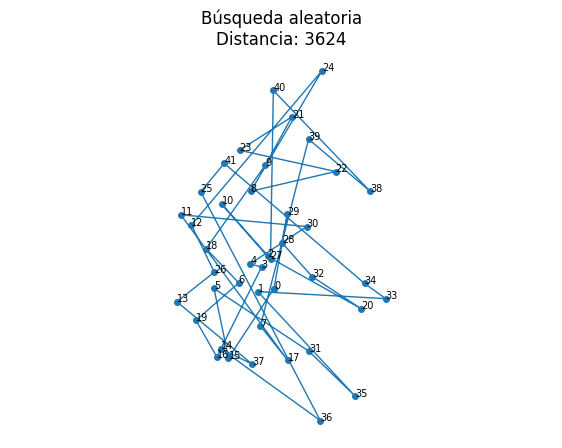

In [3]:
def busqueda_aleatoria(iteraciones, semilla=0):
    generador = random.Random(semilla)
    mejor = None
    mejor_distancia = math.inf
    for _ in range(iteraciones):
        candidata = crear_solucion(NODOS, generador)
        distancia = distancia_total(candidata)
        if distancia < mejor_distancia:
            mejor, mejor_distancia = candidata, distancia
    return mejor, mejor_distancia

solucion_aleatoria, distancia_aleatoria = busqueda_aleatoria(10_000, semilla=42)
print("Mejor distancia:", distancia_aleatoria)
dibujar_ruta(solucion_aleatoria, "Búsqueda aleatoria")

## 3. Búsqueda local con vecindad 2-opt

Un movimiento 2-opt invierte un segmento de la ruta. En cada iteración se acepta la primera mejora encontrada y el proceso termina cuando una exploración completa no produce mejoras.

Mejor distancia: 1341.0
Soluciones vecinas evaluadas: 22035


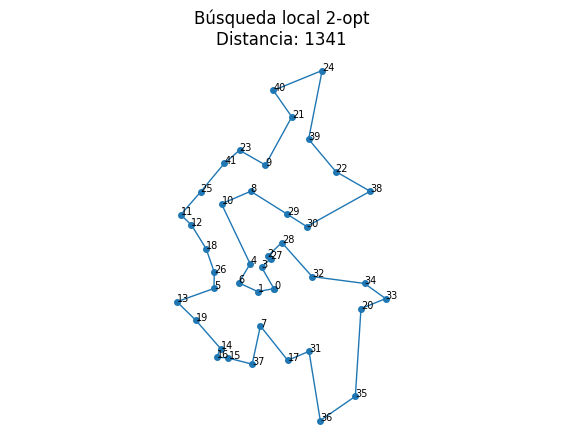

In [4]:
def movimiento_2opt(solucion, i, j):
    return solucion[:i] + list(reversed(solucion[i:j + 1])) + solucion[j + 1:]

def busqueda_local(semilla=0, solucion_inicial=None):
    generador = random.Random(semilla)
    actual = solucion_inicial[:] if solucion_inicial else crear_solucion(NODOS, generador)
    distancia_actual = distancia_total(actual)
    evaluaciones = 0

    while True:
        mejoro = False
        for i in range(1, len(actual) - 1):
            for j in range(i + 1, len(actual)):
                candidata = movimiento_2opt(actual, i, j)
                distancia = distancia_total(candidata)
                evaluaciones += 1
                if distancia < distancia_actual:
                    # Estrategia de primera mejora: se reinicia la exploración al aceptar.
                    actual, distancia_actual = candidata, distancia
                    mejoro = True
                    break
            if mejoro:
                break
        if not mejoro:
            return actual, distancia_actual, evaluaciones

solucion_local, distancia_local, evaluaciones_local = busqueda_local(semilla=42)
print("Mejor distancia:", distancia_local)
print("Soluciones vecinas evaluadas:", evaluaciones_local)
dibujar_ruta(solucion_local, "Búsqueda local 2-opt")

## 4. Recocido simulado

Las mejoras se aceptan siempre. Un empeoramiento de magnitud $\Delta$ se acepta con probabilidad $e^{-\Delta/T}$. Al reducir la temperatura disminuye gradualmente la posibilidad de abandonar la región actual.

Mejor distancia: 1397.0


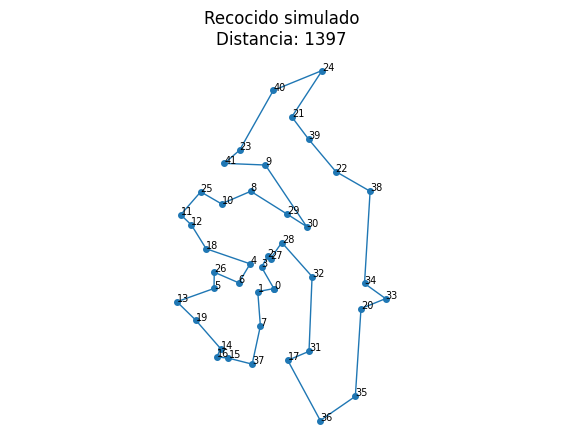

In [5]:
def recocido_simulado(
    temperatura_inicial=200,
    enfriamiento=0.9995,
    iteraciones=25_000,
    semilla=0,
):
    generador = random.Random(semilla)
    actual = crear_solucion(NODOS, generador)
    distancia_actual = distancia_total(actual)
    mejor = actual[:]
    mejor_distancia = distancia_actual
    temperatura = temperatura_inicial

    for _ in range(iteraciones):
        i, j = sorted(generador.sample(range(1, len(actual)), 2))
        candidata = movimiento_2opt(actual, i, j)
        distancia = distancia_total(candidata)
        delta = distancia - distancia_actual
        # La aceptación probabilística permite escapar temporalmente de un mínimo local.
        if delta < 0 or generador.random() < math.exp(-delta / max(temperatura, 1e-12)):
            actual, distancia_actual = candidata, distancia
        if distancia_actual < mejor_distancia:
            mejor, mejor_distancia = actual[:], distancia_actual
        temperatura *= enfriamiento
    return mejor, mejor_distancia

solucion_recocido, distancia_recocido = recocido_simulado(semilla=42)
print("Mejor distancia:", distancia_recocido)
dibujar_ruta(solucion_recocido, "Recocido simulado")

## 5. Ejercicio adicional - Comparación experimental

Como los métodos incluyen aleatoriedad, una sola ejecución no permite compararlos con suficiente información. Repito cada método con diez semillas y calculo mínimo, media y desviación estándar.

Método           Mínimo      Media      Desv.
Aleatoria        3432.0     3707.4      155.6
Local            1315.0     1358.5       30.3
Recocido         1273.0     1370.8       46.0


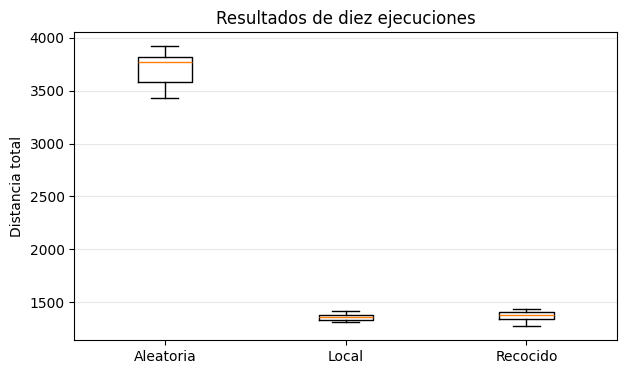

In [6]:
# Las mismas semillas reducen la variación ajena al método comparado.
resultados = {"Aleatoria": [], "Local": [], "Recocido": []}
for semilla in range(10):
    resultados["Aleatoria"].append(busqueda_aleatoria(3_000, semilla)[1])
    resultados["Local"].append(busqueda_local(semilla)[1])
    resultados["Recocido"].append(
        recocido_simulado(iteraciones=12_000, semilla=semilla)[1]
    )

print(f"{'Método':<12} {'Mínimo':>10} {'Media':>10} {'Desv.':>10}")
for metodo, valores in resultados.items():
    print(f"{metodo:<12} {min(valores):>10.1f} {mean(valores):>10.1f} {pstdev(valores):>10.1f}")

plt.figure(figsize=(7, 4))
plt.boxplot(resultados.values(), tick_labels=resultados.keys())
plt.ylabel("Distancia total")
plt.title("Resultados de diez ejecuciones")
plt.grid(axis="y", alpha=0.3)
plt.show()

La búsqueda aleatoria presenta las distancias más altas porque cada iteración comienza desde cero. La búsqueda local mejora de forma consistente, aunque puede detenerse en distintos mínimos locales. El recocido simulado acepta temporalmente soluciones peores y obtiene los mejores resultados del experimento con los parámetros utilizados.